# 02 · Feature engineering

The raw Telco columns already carry most of the signal. Here I check whether the three derived features in
`churn.features.build` earn their place, and what the model actually receives after encoding.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from churn import config

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from churn.data.ingest import X_y, load_split
from churn.features.build import DERIVED_FEATURES, add_derived_features, build_preprocessor

train = load_split("train")
derived = add_derived_features(train)
derived[DERIVED_FEATURES + ["tenure", "monthly_charges", "total_charges"]].describe().T

,count,mean,std,min,25%,50%,75%,max
avg_monthly_spend,2810.0,64.872,30.443,13.829,34.901,70.993,90.588,120.749
num_services,2816.0,3.372,2.075,0.000,1.000,3.000,5.000,8.000
is_new_customer,2816.0,0.208,0.406,0.000,0.000,0.000,0.000,1.000
tenure,2816.0,32.520,24.613,0.000,9.000,29.000,56.000,72.000
monthly_charges,2816.0,64.764,30.340,18.400,34.775,70.650,90.050,118.750
total_charges,2810.0,2297.746,2289.664,18.850,402.975,1387.125,3837.250,8684.800


## 1. `avg_monthly_spend`: what the customer actually paid per month

`total_charges / tenure` is the historical average bill. When it differs from the current `monthly_charges`, the customer's plan changed.
A recent price increase is a classic churn trigger.

In [2]:
derived["price_change"] = derived["monthly_charges"] - derived["avg_monthly_spend"]
bands = pd.cut(derived["price_change"], [-np.inf, -5, -1, 1, 5, np.inf], labels=["dropped > $5", "dropped $1-5", "stable", "rose $1-5", "rose > $5"])
derived.assign(band=bands).groupby("band", observed=True)[config.TARGET].agg(churn_rate="mean", customers="size")

,churn_rate,customers
band,,
dropped > $5,0.500,94
dropped $1-5,0.253,707
stable,0.270,1254
rose $1-5,0.219,685
rose > $5,0.471,70


The pattern is U-shaped. Customers whose bill **dropped by more than $5** churn at 50%, and customers whose bill **rose by more than $5** churn at 47%.
Both are almost double the 27% of customers with a stable bill. Any recent plan change, in either direction, is a risk signal: a downgrade often precedes
leaving, and a price increase triggers it. The groups are small (94 and 70 customers in train), so I treat this as a supporting feature, not a headline one.

## 2. `num_services`: how embedded the customer is

,churn_rate,customers
num_services,,
0,0.400,35
1,0.212,685
2,0.302,460
3,0.366,388
4,0.311,363
5,0.271,369
6,0.254,268
7,0.142,162
8,0.035,86


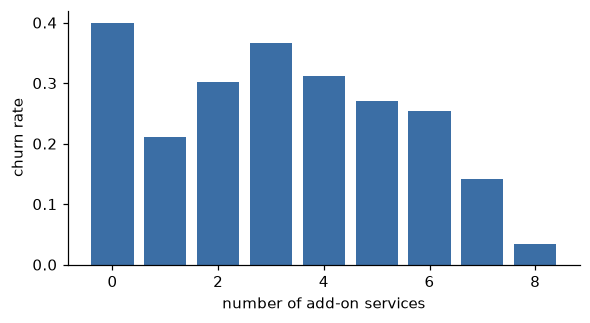

In [3]:
by_services = derived.groupby("num_services")[config.TARGET].agg(churn_rate="mean", customers="size")
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(by_services.index, by_services["churn_rate"], color="#3b6ea5")
ax.set_xlabel("number of add-on services")
ax.set_ylabel("churn rate")
by_services

Not monotonic. Churn peaks around 3 add-on services (37%) and drops sharply for fully bundled customers (14% with 7, 3.5% with 8).
The single-service group is low (21%) because 69% of it is phone-only customers without internet, who rarely churn. The count captures
"how embedded is this customer", which no single service column says on its own.

## 3. `is_new_customer`

In [4]:
derived.groupby("is_new_customer")[config.TARGET].agg(churn_rate="mean", customers="size")

,churn_rate,customers
is_new_customer,,
0,0.201,2231
1,0.509,585


## 4. Ablation: do the derived features help a linear model?

Same logistic regression, same 5 folds, with and without the derived features. Trees can find these interactions on their own;
a linear model can't, so this is where they should matter most.

In [5]:
X, y = X_y(train)
cv = StratifiedKFold(5, shuffle=True, random_state=config.RANDOM_STATE)


def without_derived():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, config.NUMERIC_FEATURES), ("cat", categorical, config.CATEGORICAL_FEATURES)])


results = {}
for name, prep in [("raw features", without_derived()), ("raw + derived", build_preprocessor())]:
    model = Pipeline([("features", prep), ("clf", LogisticRegression(max_iter=2000, C=0.5, class_weight="balanced"))])
    auc = cross_val_score(model, X, y, cv=cv, scoring="roc_auc")
    results[name] = {"cv_gini_mean": 2 * auc.mean() - 1, "cv_gini_std": 2 * auc.std()}
pd.DataFrame(results).T

,cv_gini_mean,cv_gini_std
raw features,0.683,0.026
raw + derived,0.686,0.024


For logistic regression the derived features add **0.003 Gini (0.683 → 0.686)**, well inside the fold-to-fold standard deviation of 0.024.
I'm keeping them because they're cheap, stable and interpretable, and `avg_monthly_spend` ranks among the top SHAP drivers of the tree models (notebook 04).
But I wouldn't claim they improve the model.

## 5. What the model receives

In [6]:
prep = build_preprocessor().fit(X)
names = prep.named_steps["prep"].get_feature_names_out()
print(f"{X.shape[1]} raw columns -> {len(names)} model inputs")
pd.Series(names).str.split("__", expand=True)[0].value_counts()

19 raw columns -> 49 model inputs


0
cat    43
num     6
Name: count, dtype: int64

## 6. Stability of the derived features

A feature that is stable in training but shifts in production needs monitoring. PSI of the derived features, train vs the other samples:

In [7]:
from churn.monitoring.drift import psi_numeric

samples = {name: add_derived_features(load_split(name)) for name in ["test", "holdout", "production_pool"]}
pd.DataFrame({
    name: {f: psi_numeric(derived[f], part[f]) for f in DERIVED_FEATURES}
    for name, part in samples.items()
}).round(4)

,test,holdout,production_pool
avg_monthly_spend,0.008,0.005,0.013
num_services,0.012,0.001,0.003
is_new_customer,0.000,0.000,0.000


## Summary

- 19 raw columns become 49 model inputs: 6 scaled numerics and 43 one-hot columns. Unknown categories are ignored at inference, and Pandera rejects them before that.
- Derived features are stable across samples (PSI ≤ 0.013), so they don't add monitoring risk.
- Everything is fitted inside one sklearn `Pipeline` on train only. The same object is what the batch job and the API load.